###WELCOME TO THE CADD PROJECT
This is a machine learning project aimed at drug discovery for Parkinson's Disease. The goal is to predict which drug-like molecules (compounds) might inhibit proteins linked to Parkinson's — based on how well they bind to those proteins.

## Install & Import libraries

In [5]:
# Install required libraries
!pip install rdkit --quiet

# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# RDKit for molecular processing
from rdkit import Chem
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

# Sklearn for ML
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

print("All libraries imported successfully!")

All libraries imported successfully!


## Loading **Dataset**

In [6]:
import pandas as pd

# Load the BindingDB dataset (tab-separated)
df = pd.read_csv("/content/LRRK2.tsv", sep="\t", low_memory=False, encoding='latin1')

print("Dataset shape :", df.shape)
df.head()

Dataset shape : (980, 640)


,BindingDB Reactant_set_id,Ligand SMILES,Ligand InChI,Ligand InChI Key,BindingDB MonomerID,BindingDB Ligand Name,Target Name,Target Source Organism According to Curator or DataSource,Ki (nM),IC50 (nM),...,UniProt (SwissProt) Recommended Name of Target Chain 50,UniProt (SwissProt) Entry Name of Target Chain 50,UniProt (SwissProt) Primary ID of Target Chain 50,UniProt (SwissProt) Secondary ID(s) of Target Chain 50,UniProt (SwissProt) Alternative ID(s) of Target Chain 50,UniProt (TrEMBL) Submitted Name of Target Chain 50,UniProt (TrEMBL) Entry Name of Target Chain 50,UniProt (TrEMBL) Primary ID of Target Chain 50,UniProt (TrEMBL) Secondary ID(s) of Target Chain 50,UniProt (TrEMBL) Alternative ID(s) of Target Chain 50
0,51253006,C[C@@H](Oc1cc(ccc1Nc1nc(O[C@H]2CC[C@@](C)(O)CC...,"InChI=1S/C25H29ClF3N5O4/c1-13(25(27,28)29)37-1...",IUWWRSQCDUQDEZ-CAQPCFEESA-N,50512318,CHEMBL4546504,Leucine-rich repeat serine/threonine-protein k...,Homo sapiens,NaN,0.001,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,51252997,C[C@@H](Oc1cc(ccc1Nc1nc(O[C@H]2CC[C@@](C)(O)CC...,"InChI=1S/C25H29ClF3N5O4/c1-13(25(27,28)29)37-1...",IUWWRSQCDUQDEZ-CAQPCFEESA-N,50512318,CHEMBL4546504,Leucine-rich repeat serine/threonine-protein k...,Homo sapiens,NaN,0.001,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,51146392,Cc1cccc(c1)-c1cc(Nc2ccn(C)n2)nc2[nH]cc(C#N)c12,InChI=1S/C19H16N6/c1-12-4-3-5-13(8-12)15-9-17(...,IQBHNQCIUDQGPV-UHFFFAOYSA-N,254931,"US9499542, 14::US9675594, 14",Leucine-rich repeat serine/threonine-protein k...,Homo sapiens,0.06,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,51481503,CC1NN=CC1Nc1ncc2cc(Cl)c(cc2n1)N1CCC(C)(O)C(C)C1,"InChI=1S/C19H25ClN6O/c1-11-10-26(5-4-19(11,3)2...",MPCUNIBDWNYAQP-UHFFFAOYSA-N,50597001,CHEMBL5189225,Leucine-rich repeat serine/threonine-protein k...,Homo sapiens,NaN,0.064565,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,51481500,CC(C)(O)CN1CCN(CC1)c1cc2nc(Nc3cnn(C4CC4)c3Cl)n...,"InChI=1S/C22H27Cl2N7O/c1-22(2,32)13-29-5-7-30(...",WFSZOUHEJNHWSD-UHFFFAOYSA-N,50596998,CHEMBL5195441,Leucine-rich repeat serine/threonine-protein k...,Homo sapiens,NaN,0.075858,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Select relevant columns

In [7]:
# We only need 3 columns:
# - Ligand SMILES  : molecule structure
# - IC50 (nM)      : binding potency (target variable)
# - BindingDB Reactant_set_id : molecule ID

df = df[["BindingDB Reactant_set_id", "Ligand SMILES", "IC50 (nM)"]].copy()

print("Shape after column selection :", df.shape)
df.head()

Shape after column selection : (980, 3)


,BindingDB Reactant_set_id,Ligand SMILES,IC50 (nM)
0,51253006,C[C@@H](Oc1cc(ccc1Nc1nc(O[C@H]2CC[C@@](C)(O)CC...,0.001
1,51252997,C[C@@H](Oc1cc(ccc1Nc1nc(O[C@H]2CC[C@@](C)(O)CC...,0.001
2,51146392,Cc1cccc(c1)-c1cc(Nc2ccn(C)n2)nc2[nH]cc(C#N)c12,NaN
3,51481503,CC1NN=CC1Nc1ncc2cc(Cl)c(cc2n1)N1CCC(C)(O)C(C)C1,0.064565
4,51481500,CC(C)(O)CN1CCN(CC1)c1cc2nc(Nc3cnn(C4CC4)c3Cl)n...,0.075858


##  Clean the data

In [8]:
# ── Step 1: Drop rows with missing values ─────────────────────────────────
df = df.dropna()
print("After dropping NaN       :", len(df))

# ── Step 2: Remove duplicate molecules ────────────────────────────────────
df = df.drop_duplicates(subset="Ligand SMILES")
print("After dropping duplicates :", len(df))

# ── Step 3: Clean IC50 column — remove >, <, ~ symbols ───────────────────
# Some IC50 values are stored as strings like '>3000' or '<100'
df["IC50 (nM)"] = (
    df["IC50 (nM)"]
    .astype(str)
    .str.replace(">", "", regex=False)
    .str.replace("<", "", regex=False)
    .str.replace("~", "", regex=False)
    .str.strip()
)

# ── Step 4: Convert IC50 to numeric (invalid → NaN) ───────────────────────
df["IC50 (nM)"] = pd.to_numeric(df["IC50 (nM)"], errors="coerce")

# ── Step 5: Drop rows where IC50 is still NaN after conversion ────────────
df = df.dropna(subset=["IC50 (nM)"])
print("After IC50 cleaning       :", len(df))

# ── Step 6: Reset index cleanly ───────────────────────────────────────────
df = df.reset_index(drop=True)

print("\nSample IC50 values:")
print(df["IC50 (nM)"].describe())

After dropping NaN       : 941
After dropping duplicates : 877
After IC50 cleaning       : 877

Sample IC50 values:
count    877.000000
mean      47.640400
std       18.886639
min        0.001000
25%       50.000000
50%       55.000000
75%       60.000000
max       60.000000
Name: IC50 (nM), dtype: float64


## Convert IC50 to pIC50

Final dataset shape : (877, 4)

pIC50 distribution:
count    877.000000
mean       7.555243
std        0.777623
min        7.221849
25%        7.221849
50%        7.259637
75%        7.301030
max       12.000000
Name: pIC50, dtype: float64


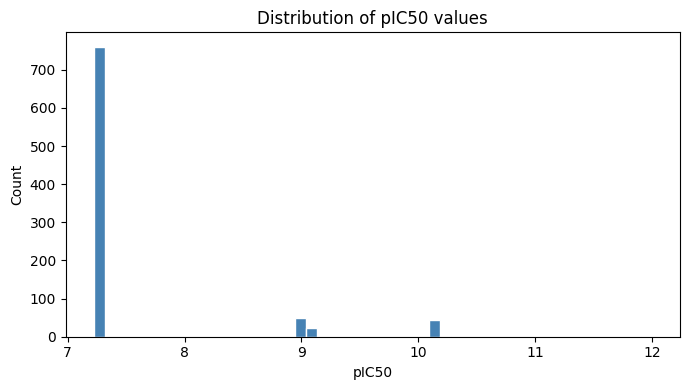

In [9]:






# IC50 ranges from 1 to 1,000,000+ nM — too wide for ML
# pIC50 = -log10(IC50 in Molar) compresses this into a clean range
# Higher pIC50 = more potent compound

df["pIC50"] = -np.log10(df["IC50 (nM)"] / 1e9)

# Drop rows where pIC50 is NaN or infinite
df = df[df["pIC50"].notna() & np.isfinite(df["pIC50"])]
df = df.reset_index(drop=True)

print("Final dataset shape :", df.shape)
print("\npIC50 distribution:")
print(df["pIC50"].describe())

# Plot pIC50 distribution
plt.figure(figsize=(7, 4))
plt.hist(df["pIC50"], bins=50, color="steelblue", edgecolor="white")
plt.xlabel("pIC50")
plt.ylabel("Count")
plt.title("Distribution of pIC50 values")
plt.tight_layout()
plt.show()

In [10]:
df

,BindingDB Reactant_set_id,Ligand SMILES,IC50 (nM),pIC50
0,51253006,C[C@@H](Oc1cc(ccc1Nc1nc(O[C@H]2CC[C@@](C)(O)CC...,0.001000,12.000000
1,51481503,CC1NN=CC1Nc1ncc2cc(Cl)c(cc2n1)N1CCC(C)(O)C(C)C1,0.064565,10.190003
2,51481500,CC(C)(O)CN1CCN(CC1)c1cc2nc(Nc3cnn(C4CC4)c3Cl)n...,0.075858,10.119999
3,1159312,Cc1cc2cnc(NC(=O)[C@@H]3C[C@H]3c3ccn(C)n3)cc2cc...,0.080000,10.096910
4,1159315,C[C@H]1[C@H]([C@@H]1c1ccn(C)n1)C(=O)Nc1cc2cc(N...,0.080000,10.096910
...,...,...,...,...
872,1127865,CCNc1nc(Nc2cnn([C@H]3C[C@@H](C3)N3CC[C@@H](F)C...,60.000000,7.221849
873,1127864,CCNc1nc(Nc2cnn([C@@H]3C[C@@H](C3)N3CC[C@H](F)C...,60.000000,7.221849
874,1127867,CNc1nc(Nc2cnn(c2C)[C@](C)(C#N)C(F)F)ncc1C(F)(F)F,60.000000,7.221849
875,1127866,CCNc1nc(Nc2cnn([C@@H]3C[C@@H](C3)N3CC[C@@H](F)...,60.000000,7.221849


## Convert SMILES to Morgan Fingerprints

In [11]:
# Parse SMILES strings into RDKit mol objects
df["mol"] = df["Ligand SMILES"].apply(lambda x: Chem.MolFromSmiles(str(x)))

# Drop rows where SMILES could not be parsed
df = df[df["mol"].notnull()].reset_index(drop=True)
print("After mol parsing :", len(df))

# Generate Morgan Fingerprints
# radius=2 captures chemical neighbourhood within 2 bonds (standard for drug data)
# fpSize=2048 gives a 2048-bit binary vector per molecule
morgan_gen = GetMorganGenerator(radius=2, fpSize=2048)

fingerprints = []
for mol in df["mol"]:
    fp = morgan_gen.GetFingerprint(mol)
    fingerprints.append(fp.ToList())

print("Fingerprints generated :", len(fingerprints))

After mol parsing : 877
Fingerprints generated : 877


## Build final feature dataframe

In [12]:
# Convert fingerprints list into a dataframe
fp_df = pd.DataFrame(fingerprints)

# Remove columns that are always 0 (zero variance — carry no information)
fp_df = fp_df.loc[:, (fp_df != 0).any(axis=0)]
print("Fingerprint columns after removing zero-variance :", fp_df.shape[1])

# Attach pIC50 as the target column
# Using .values ensures index alignment is position-based (safe)
fp_df["pIC50"] = df["pIC50"].values

# Final reset
fp_df = fp_df.reset_index(drop=True)

print("\nFinal dataframe shape :", fp_df.shape)
print("pIC50 nulls           :", fp_df["pIC50"].isna().sum())
fp_df.head()

Fingerprint columns after removing zero-variance : 1641

Final dataframe shape : (877, 1642)
pIC50 nulls           : 0


,0,1,2,3,4,5,7,8,9,10,...,2036,2039,2040,2041,2042,2043,2044,2045,2047,pIC50
0,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,12.000000
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,10.190003
2,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,10.119999
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,10.096910
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,10.096910


## Train / Test split

In [13]:
# Separate features (X) from target (y)
X = fp_df.drop(columns=["pIC50"])
y = fp_df["pIC50"]

# 80% training, 20% testing
# random_state=42 ensures reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples :", X_train.shape[0])
print("Testing samples  :", X_test.shape[0])
print("Features         :", X_train.shape[1])

Training samples : 701
Testing samples  : 176
Features         : 1641


## Define all model pipelines

In [14]:
# Each pipeline = StandardScaler + Model
# StandardScaler normalises features — important for Linear, SVR, KNN
# Random Forest and Gradient Boosting don't strictly need it but it doesn't hurt

pipelines = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  Ridge(alpha=1.0))
    ]),
    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  Lasso(alpha=0.01, max_iter=5000))
    ]),
    "KNN Regressor": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  KNeighborsRegressor(n_neighbors=5))
    ]),
    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  SVR(kernel="rbf", C=10, epsilon=0.1))
    ]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
    ]),
    "Gradient Boosting": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42))
    ]),
}

print(f"{len(pipelines)} models ready to train.")

7 models ready to train.


## Train & evaluate all models

In [15]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, pipeline in pipelines.items():
    print(f"Training : {name} ...")

    # 5-fold cross validation on training set
    cv_scores = cross_val_score(
        pipeline, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1
    )

    # Fit on full training set
    pipeline.fit(X_train, y_train)

    # Predict on test set
    y_pred    = pipeline.predict(X_test)
    test_r2   = r2_score(y_test, y_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results.append({
        "Model"      : name,
        "CV R² Mean" : round(cv_scores.mean(), 4),
        "CV R² Std"  : round(cv_scores.std(),  4),
        "Test R²"    : round(test_r2,           4),
        "Test RMSE"  : round(test_rmse,         4),
    })

    print(f"   CV R²: {cv_scores.mean():.4f} ± {cv_scores.std():.4f} | Test R²: {test_r2:.4f} | RMSE: {test_rmse:.4f}\n")

# Summary table sorted by Test R²
results_df = pd.DataFrame(results).sort_values("Test R²", ascending=False)
print("=" * 65)
print(results_df.to_string(index=False))

Training : Linear Regression ...
   CV R²: 0.7013 ± 0.1536 | Test R²: 0.5881 | RMSE: 0.5289

Training : Ridge Regression ...
   CV R²: 0.7028 ± 0.1546 | Test R²: 0.5900 | RMSE: 0.5276

Training : Lasso Regression ...
   CV R²: 0.7188 ± 0.1734 | Test R²: 0.6898 | RMSE: 0.4590

Training : KNN Regressor ...
   CV R²: 0.6793 ± 0.1129 | Test R²: 0.5932 | RMSE: 0.5256

Training : SVR ...
   CV R²: 0.6710 ± 0.1101 | Test R²: 0.6134 | RMSE: 0.5124

Training : Random Forest ...
   CV R²: 0.7734 ± 0.1794 | Test R²: 0.7572 | RMSE: 0.4060

Training : Gradient Boosting ...
   CV R²: 0.7387 ± 0.2010 | Test R²: 0.7457 | RMSE: 0.4155

            Model  CV R² Mean  CV R² Std  Test R²  Test RMSE
    Random Forest      0.7734     0.1794   0.7572     0.4060
Gradient Boosting      0.7387     0.2010   0.7457     0.4155
 Lasso Regression      0.7188     0.1734   0.6898     0.4590
              SVR      0.6710     0.1101   0.6134     0.5124
    KNN Regressor      0.6793     0.1129   0.5932     0.5256
 Ridge 

## Visualise model comparison

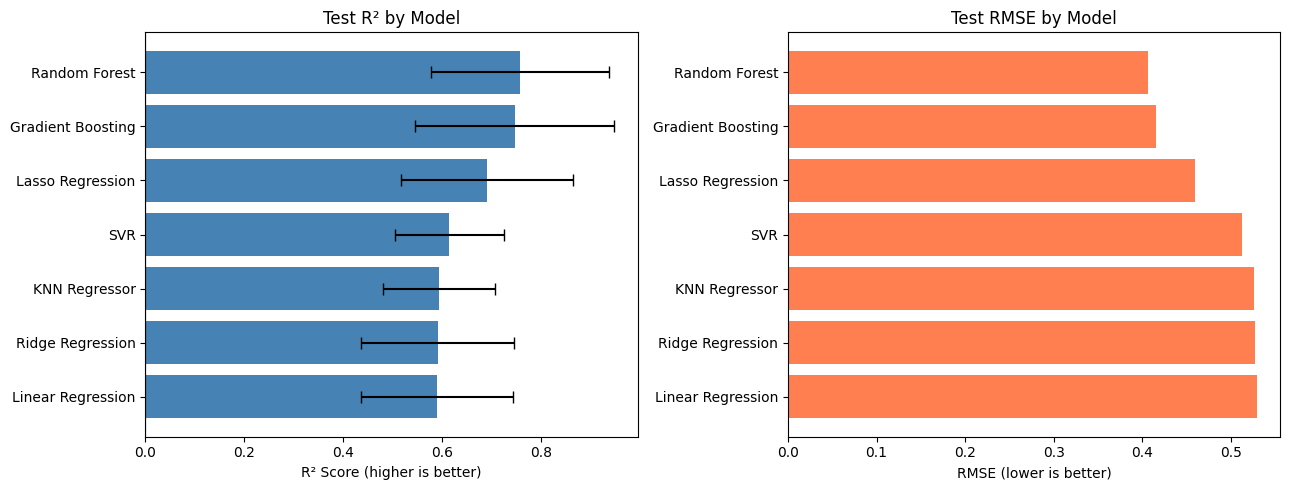

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# R² bar chart
axes[0].barh(results_df["Model"], results_df["Test R²"],
             xerr=results_df["CV R² Std"], color="steelblue", capsize=4)
axes[0].set_xlabel("R² Score (higher is better)")
axes[0].set_title("Test R² by Model")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].invert_yaxis()

# RMSE bar chart
axes[1].barh(results_df["Model"], results_df["Test RMSE"],
             color="coral")
axes[1].set_xlabel("RMSE (lower is better)")
axes[1].set_title("Test RMSE by Model")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

## What are Molecular Descriptors?

Unlike fingerprints (which are binary yes/no features), molecular descriptors are actual numerical properties of a molecule — like molecular weight, number of hydrogen bond donors, lipophilicity, ring count etc. They give the model richer, more chemically meaningful information.


## Calculate Molecular Descriptors using RDKit
 Using RDKit has 200+ built-in descriptors. We calculate all of them for every molecule.

In [17]:
from rdkit.Chem import Descriptors
from rdkit.ML.Descriptors import MoleculeDescriptors
import pandas as pd
import numpy as np

# Get list of all available descriptor names
descriptor_names = [name for name, _ in Descriptors.descList]
print(f"Total descriptors available: {len(descriptor_names)}")

# Create descriptor calculator
calculator = MoleculeDescriptors.MolecularDescriptorCalculator(descriptor_names)

# Calculate descriptors for every molecule
descriptor_values = []
for mol in df["mol"]:
    descriptors = calculator.CalcDescriptors(mol)
    descriptor_values.append(descriptors)

# Build dataframe
desc_df = pd.DataFrame(descriptor_values, columns=descriptor_names)
print("Descriptor dataframe shape:", desc_df.shape)
desc_df.head()

Total descriptors available: 217
Descriptor dataframe shape: (877, 217)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,13.287014,13.287014,0.018537,-4.624115,0.354754,20.710526,555.985,526.753,555.186017,206,...,0,0,0,0,0,0,0,0,0,0
1,10.437972,10.437972,0.054996,-0.632293,0.749038,30.555556,388.903,363.703,388.177837,144,...,0,0,0,0,0,0,0,0,0,0
2,10.085564,10.085564,0.406657,-0.693317,0.554397,17.843750,476.412,449.196,475.165414,170,...,0,0,0,0,0,0,0,0,0,0
3,14.486136,14.486136,0.003227,-0.942166,0.589410,28.555556,492.599,459.335,492.264903,190,...,0,0,0,0,0,0,0,0,0,0
4,13.022593,13.022593,0.021401,-0.470093,0.529583,30.135135,525.053,491.789,524.230267,196,...,0,0,0,0,0,0,0,0,0,0


## Clean the Descriptor Dataframe
Some descriptors produce NaN or infinite values for certain molecules. We drop those.

In [18]:
# Replace infinities with NaN
desc_df = desc_df.replace([np.inf, -np.inf], np.nan)

# Drop columns where more than 10% of values are NaN
threshold = 0.1
desc_df = desc_df.dropna(thresh=int((1 - threshold) * len(desc_df)), axis=1)

# Drop remaining rows that still have NaN
desc_df = desc_df.dropna(axis=0).reset_index(drop=True)

print("After cleaning shape:", desc_df.shape)

After cleaning shape: (877, 217)


## Remove Low Variance Features
Descriptors that barely change across molecules carry no useful information for the model.

In [19]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.01)
desc_array = selector.fit_transform(desc_df)

selected_columns = desc_df.columns[selector.get_support()]
desc_df_clean = pd.DataFrame(desc_array, columns=selected_columns)

print("Before variance filter:", desc_df.shape[1], "features")
print("After variance filter :", desc_df_clean.shape[1], "features")

Before variance filter: 217 features
After variance filter : 160 features


## Attach pIC50
We need to align pIC50 with the cleaned descriptor rows carefully.
python

In [20]:
# Align pIC50 with desc_df_clean using df index
pic50_values = df["pIC50"].reset_index(drop=True)

# desc_df may have dropped some rows — reindex to match
desc_df_clean = desc_df_clean.reset_index(drop=True)
pic50_aligned = pic50_values.iloc[:len(desc_df_clean)].reset_index(drop=True)

desc_df_clean["pIC50"] = pic50_aligned

# Drop any remaining NaN in pIC50
desc_df_clean = desc_df_clean[
    desc_df_clean["pIC50"].notna() & np.isfinite(desc_df_clean["pIC50"])
].reset_index(drop=True)

print("Final dataset shape:", desc_df_clean.shape)
desc_df_clean.head()

Final dataset shape: (877, 161)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_nitrile,fr_para_hydroxylation,fr_piperdine,fr_piperzine,fr_priamide,fr_pyridine,fr_sulfonamd,fr_sulfone,fr_thiazole,pIC50
0,13.287014,13.287014,0.018537,-4.624115,0.354754,20.710526,555.985,526.753,555.186017,206.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.000000
1,10.437972,10.437972,0.054996,-0.632293,0.749038,30.555556,388.903,363.703,388.177837,144.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,10.190003
2,10.085564,10.085564,0.406657,-0.693317,0.554397,17.843750,476.412,449.196,475.165414,170.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,10.119999
3,14.486136,14.486136,0.003227,-0.942166,0.589410,28.555556,492.599,459.335,492.264903,190.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,10.096910
4,13.022593,13.022593,0.021401,-0.470093,0.529583,30.135135,525.053,491.789,524.230267,196.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,10.096910


## Train / Test Split

In [21]:
from sklearn.model_selection import train_test_split

X = desc_df_clean.drop(columns=["pIC50"])
y = desc_df_clean["pIC50"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

X_train shape: (701, 160)
X_test shape : (176, 160)


## Define All Model Pipelines

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

pipelines = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  Ridge(alpha=1.0))
    ]),
    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  Lasso(alpha=0.01, max_iter=5000))
    ]),
    "KNN Regressor": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  KNeighborsRegressor(n_neighbors=5))
    ]),
    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  SVR(kernel="rbf", C=10, epsilon=0.1))
    ]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
    ]),
    "Gradient Boosting": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42))
    ]),
}

## Train & Cross-Validate All Models

In [23]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, r2_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, pipeline in pipelines.items():
    print(f"Training: {name}...")

    # 5-fold cross validation
    cv_scores = cross_val_score(pipeline, X_train, y_train,
                                cv=kf, scoring="r2", n_jobs=-1)

    # Fit on full training set
    pipeline.fit(X_train, y_train)

    # Evaluate on test set
    y_pred    = pipeline.predict(X_test)
    test_r2   = r2_score(y_test, y_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results.append({
        "Model"      : name,
        "CV R² Mean" : round(cv_scores.mean(), 4),
        "CV R² Std"  : round(cv_scores.std(),  4),
        "Test R²"    : round(test_r2,           4),
        "Test RMSE"  : round(test_rmse,         4),
    })

    print(f"  CV R²: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  Test R²: {test_r2:.4f}  |  Test RMSE: {test_rmse:.4f}\n")

results_df = pd.DataFrame(results).sort_values("Test R²", ascending=False)
print("\n===== Model Comparison =====")
print(results_df.to_string(index=False))

Training: Linear Regression...
  CV R²: -0.1052 ± 0.8149
  Test R²: 0.6434  |  Test RMSE: 0.4921

Training: Ridge Regression...
  CV R²: 0.5019 ± 0.2336
  Test R²: 0.6622  |  Test RMSE: 0.4789

Training: Lasso Regression...
  CV R²: 0.6145 ± 0.0993
  Test R²: 0.6357  |  Test RMSE: 0.4974

Training: KNN Regressor...
  CV R²: 0.6964 ± 0.1741
  Test R²: 0.6589  |  Test RMSE: 0.4813

Training: SVR...
  CV R²: 0.7347 ± 0.1462
  Test R²: 0.6079  |  Test RMSE: 0.5160

Training: Random Forest...
  CV R²: 0.6951 ± 0.1026
  Test R²: 0.6020  |  Test RMSE: 0.5199

Training: Gradient Boosting...
  CV R²: 0.6866 ± 0.1301
  Test R²: 0.5260  |  Test RMSE: 0.5673


===== Model Comparison =====
            Model  CV R² Mean  CV R² Std  Test R²  Test RMSE
 Ridge Regression      0.5019     0.2336   0.6622     0.4789
    KNN Regressor      0.6964     0.1741   0.6589     0.4813
Linear Regression     -0.1052     0.8149   0.6434     0.4921
 Lasso Regression      0.6145     0.0993   0.6357     0.4974
         

## Visualise Model Comparison

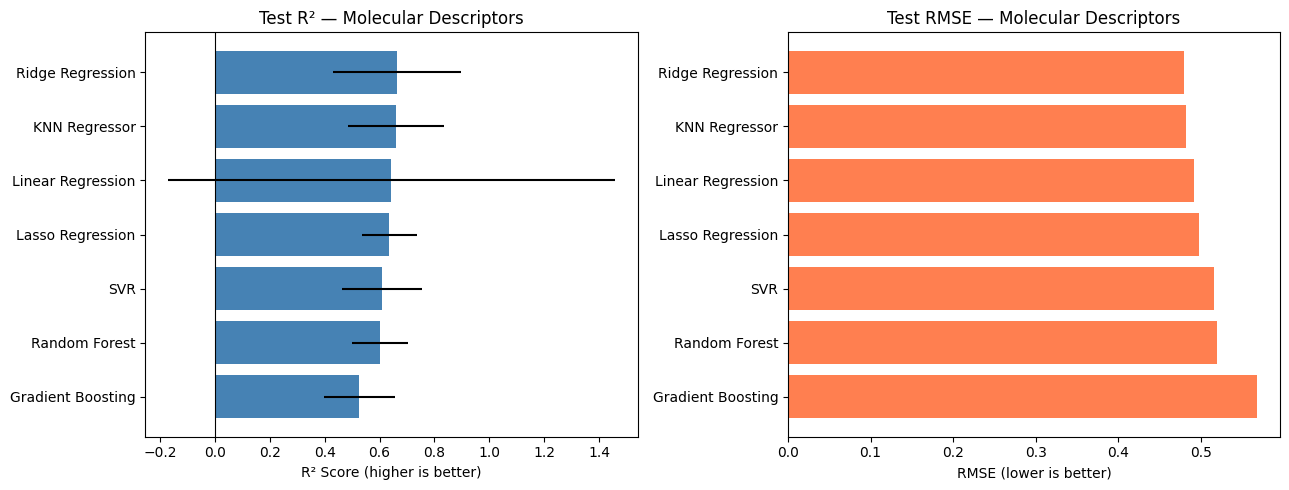

In [24]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].barh(results_df["Model"], results_df["Test R²"],
             xerr=results_df["CV R² Std"], color="steelblue")
axes[0].set_xlabel("R² Score (higher is better)")
axes[0].set_title("Test R² — Molecular Descriptors")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].invert_yaxis()

axes[1].barh(results_df["Model"], results_df["Test RMSE"], color="coral")
axes[1].set_xlabel("RMSE (lower is better)")
axes[1].set_title("Test RMSE — Molecular Descriptors")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("descriptor_model_comparison.png", dpi=150)
plt.show()

## Calculate Molecular Descriptors using Padelpy

In [25]:
!pip install padelpy
from padelpy import from_smiles
import pandas as pd
import numpy as np
import time
import os

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.9/20.9 MB 73.5 MB/s eta 0:00:00


## Preparing the SMILES list (first 1650 rows)

In [26]:
# Take rows 1 to 1650
df_1to1650  = df.iloc[0:1650].reset_index(drop=True)

smiles_list = df_1to1650["Ligand SMILES"].tolist()

print(f"Total SMILES to process: {len(smiles_list)}")
print("Sample:", smiles_list[0])

Total SMILES to process: 877
Sample: C[C@@H](Oc1cc(ccc1Nc1nc(O[C@H]2CC[C@@](C)(O)CC2)c2c(Cl)c[nH]c2n1)C(=O)N(C)C)C(F)(F)F


## ⚙️ Batch Processing Setup — Molecular Descriptor Generation

This section sets up the core pipeline for generating **PaDEL molecular descriptors** from SMILES strings using a batch processing approach.

### Why Batch Processing?
PaDEL-Descriptor processes each molecule individually through a Java engine, which is computationally intensive. To avoid:
- ⏱️ Session timeouts on Google Colab
- 💥 Memory crashes on large datasets
- ❌ Loss of progress on failure

...we split the full dataset into **smaller batches of 200 molecules each**, process them independently, and save a checkpoint CSV after every batch.

### What This Cell Does
| Component | Purpose |
|---|---|
| `split_into_batches()` | Dynamically splits SMILES list into batches of 200 |
| `generate_descriptors_for_batch()` | Runs PaDEL on one batch, molecule by molecule |
| **Checkpoint saving** | Saves `batch_N_checkpoint.csv` after each batch completes |
| **Progress saving** | Saves a temp file every 50 molecules within a batch |
| **Crash recovery** | Automatically skips batches that are already completed |



## Output
Each batch produces a CSV file:

In [27]:
# DYNAMIC SPLIT — batch size 200
def split_into_batches(smiles_list, batch_size=200):
    total   = len(smiles_list)
    batches = [smiles_list[i : i + batch_size] for i in range(0, total, batch_size)]
    print(f"Total SMILES available : {total}")
    print(f"Batch size             : {batch_size}")
    print(f"Total batches created  : {len(batches)}")
    for idx, b in enumerate(batches):
        print(f"  Batch {idx+1} size: {len(b)}")
    return batches

batches = split_into_batches(smiles_list, batch_size=200)

# DESCRIPTOR GENERATION FUNCTION
def generate_descriptors_for_batch(batch_smiles, batch_num):
    save_file = f"batch_{batch_num}_checkpoint.csv"

    if os.path.exists(save_file):
        print(f"Batch {batch_num} already done — loading from checkpoint ✓")
        return pd.read_csv(save_file)

    print(f"\nProcessing Batch {batch_num} ({len(batch_smiles)} molecules)...")
    descriptor_rows = []
    failed          = 0

    for i, smi in enumerate(batch_smiles):
        try:
            result = from_smiles([smi], descriptors=True, fingerprints=False, timeout=60)
            row_df = pd.DataFrame(result)
            row_df.insert(0, "Ligand SMILES", smi)
            row_df.insert(1, "Batch", batch_num)
            descriptor_rows.append(row_df)
        except Exception as e:
            print(f"  PaDEL failed for row {i} ({smi[:30]}...): {e}")
            failed += 1

        if descriptor_rows and (i + 1) % 50 == 0:
            temp_df = pd.concat(descriptor_rows, ignore_index=True)
            temp_df.to_csv(f"batch_{batch_num}_temp.csv", index=False)
            print(f"  Progress: {i+1}/{len(batch_smiles)} saved ✓")

        time.sleep(0.3)

    print(f"  Batch {batch_num} done — success: {len(descriptor_rows)}, failed: {failed}")

    if descriptor_rows:
        final_df = pd.concat(descriptor_rows, ignore_index=True)
        final_df.to_csv(save_file, index=False)
        print(f"  ✓ Checkpoint saved: {save_file}")
        return final_df
    else:
        return pd.DataFrame()

print("\n✓ Setup complete — ready to run batch cells")

Total SMILES available : 877
Batch size             : 200
Total batches created  : 5
  Batch 1 size: 200
  Batch 2 size: 200
  Batch 3 size: 200
  Batch 4 size: 200
  Batch 5 size: 77

✓ Setup complete — ready to run batch cells


In [28]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Batch 1 (rows 1–200)

In [29]:
print("=" * 50)
print("CELL 1 — Batch 1 (rows 1–200)")
print("=" * 50)

desc_batch1 = generate_descriptors_for_batch(batches[0], batch_num=1)
print(f"\n✓ Batch 1 shape: {desc_batch1.shape if not desc_batch1.empty else 'empty'}")

CELL 1 — Batch 1 (rows 1–200)

Processing Batch 1 (200 molecules)...
  Progress: 50/200 saved ✓
  Progress: 100/200 saved ✓
  Progress: 150/200 saved ✓
  Progress: 200/200 saved ✓
  Batch 1 done — success: 200, failed: 0
  ✓ Checkpoint saved: batch_1_checkpoint.csv

✓ Batch 1 shape: (200, 1877)


### Batch 2 (rows 201–400)

In [30]:
print("=" * 50)
print("CELL 2 — Batch 2 (rows 201–400)")
print("=" * 50)

desc_batch2 = generate_descriptors_for_batch(batches[1], batch_num=2)
print(f"\n✓ Batch 2 shape: {desc_batch2.shape if not desc_batch2.empty else 'empty'}")

CELL 2 — Batch 2 (rows 201–400)

Processing Batch 2 (200 molecules)...
  Progress: 50/200 saved ✓
  Progress: 100/200 saved ✓
  Progress: 150/200 saved ✓
  Progress: 200/200 saved ✓
  Batch 2 done — success: 200, failed: 0
  ✓ Checkpoint saved: batch_2_checkpoint.csv

✓ Batch 2 shape: (200, 1877)


###Batch 3 (rows 401–600)

In [31]:
print("=" * 50)
print("CELL 3 — Batch 3 (rows 401–600)")
print("=" * 50)

desc_batch3 = generate_descriptors_for_batch(batches[2], batch_num=3)
print(f"\n✓ Batch 3 shape: {desc_batch3.shape if not desc_batch3.empty else 'empty'}")

CELL 3 — Batch 3 (rows 401–600)

Processing Batch 3 (200 molecules)...
  Progress: 50/200 saved ✓
  Progress: 100/200 saved ✓
  Progress: 150/200 saved ✓
  Progress: 200/200 saved ✓
  Batch 3 done — success: 200, failed: 0
  ✓ Checkpoint saved: batch_3_checkpoint.csv

✓ Batch 3 shape: (200, 1877)


###Batch 4 (rows 601–800)

In [32]:
print("=" * 50)
print("CELL 4 — Batch 4 (rows 601–800)")
print("=" * 50)

desc_batch4 = generate_descriptors_for_batch(batches[3], batch_num=4)
print(f"\n✓ Batch 4 shape: {desc_batch4.shape if not desc_batch4.empty else 'empty'}")

CELL 4 — Batch 4 (rows 601–800)

Processing Batch 4 (200 molecules)...
  Progress: 50/200 saved ✓
  Progress: 100/200 saved ✓
  Progress: 150/200 saved ✓
  Progress: 200/200 saved ✓
  Batch 4 done — success: 200, failed: 0
  ✓ Checkpoint saved: batch_4_checkpoint.csv

✓ Batch 4 shape: (200, 1877)


###Batch 5 (rows 801–1000)

In [33]:
print("=" * 50)
print("CELL 5 — Batch 5 (rows 801–1000)")
print("=" * 50)

desc_batch5 = generate_descriptors_for_batch(batches[4], batch_num=5)
print(f"\n✓ Batch 5 shape: {desc_batch5.shape if not desc_batch5.empty else 'empty'}")

CELL 5 — Batch 5 (rows 801–1000)

Processing Batch 5 (77 molecules)...
  Progress: 50/77 saved ✓
  Batch 5 done — success: 77, failed: 0
  ✓ Checkpoint saved: batch_5_checkpoint.csv

✓ Batch 5 shape: (77, 1877)


 ## Load & Concatenate  CSV Files

In [36]:
import numpy as np
import pandas as pd
import os

print("=" * 60)
print(" Load & Concatenate Available Batch CSVs")
print("=" * 60)

all_dfs_to_concat = []

# --- Load batch_1_checkpoint.csv to batch_5_checkpoint.csv (representing padel_descriptors_1650.csv conceptually) ---
temp_dfs_batch1_to_5 = []
for i in range(1, 6): # Assuming batches 1 to 5 correspond to the first block
    file_name = f"batch_{i}_checkpoint.csv"
    if os.path.exists(file_name):
        batch_df = pd.read_csv(file_name)
        temp_dfs_batch1_to_5.append(batch_df)
        print(f"  Loaded {file_name} — shape: {batch_df.shape}")
    else:
        print(f"  Skipped {file_name} — not found")

if temp_dfs_batch1_to_5:
    df1 = pd.concat(temp_dfs_batch1_to_5, ignore_index=True)
    all_dfs_to_concat.append(df1)
    print(f"  Combined 'padel_descriptors_1650.csv' (from batches 1-5) shape: {df1.shape}")
else:
    df1 = pd.DataFrame() # Explicitly define df1 even if empty
    print("  No files for conceptual 'padel_descriptors_1650.csv' (batches 1-5) found.")


# --- Load padel_descriptors_1651_3300.csv from Google Drive -----------------------------------------------
# This file was saved in cell 7ucke5OuE1MZ
base_path_drive = "/content/drive/MyDrive/padel_batches/"
file_path_df2 = os.path.join(base_path_drive, "padel_descriptors_1651_3300.csv")

if os.path.exists(file_path_df2):
    df2 = pd.read_csv(file_path_df2)
    all_dfs_to_concat.append(df2)
    print(f"  Loaded {os.path.basename(file_path_df2)} — shape: {df2.shape}")
else:
    df2 = pd.DataFrame() # Explicitly define df2 even if empty
    print(f"  Skipped {os.path.basename(file_path_df2)} — not found at {file_path_df2}")

# --- Placeholder for other files (assuming they are not generated based on deleted cells) ----------------
# If 'padel_descriptors_3301_4951.csv' or 'padel_descriptors_4951_to_6640.csv' were to exist,
# they would be loaded and added to all_dfs_to_concat here.
# For now, we assume they haven't been generated successfully.
print("  Note: 'padel_descriptors_3301_4951.csv' and 'padel_descriptors_4951_to_6640.csv' were not found and are not loaded.")

# --- Concatenate all available dataframes -----------------------------------------------------------------
if all_dfs_to_concat:
    combined_df = pd.concat(all_dfs_to_concat, ignore_index=True)
    print(f"\n✓ Combined shape  : {combined_df.shape}")
    print(f"  Total rows      : {combined_df.shape[0]}")
    print(f"  Total columns   : {combined_df.shape[1]}")
    print(f"  pIC50 present   : {'pIC50' in combined_df.columns}")
    print(f"  NaN count       : {combined_df.isnull().sum().sum()}")
    print("Combined DataFrame head:")
    print(combined_df.head())
else:
    combined_df = pd.DataFrame()
    print("\nNo dataframes were loaded or available for concatenation.")

 Load & Concatenate Available Batch CSVs
  Loaded batch_1_checkpoint.csv — shape: (200, 1877)
  Loaded batch_2_checkpoint.csv — shape: (200, 1877)
  Loaded batch_3_checkpoint.csv — shape: (200, 1877)
  Loaded batch_4_checkpoint.csv — shape: (200, 1877)
  Loaded batch_5_checkpoint.csv — shape: (77, 1877)
  Combined 'padel_descriptors_1650.csv' (from batches 1-5) shape: (877, 1877)
  Skipped padel_descriptors_1651_3300.csv — not found at /content/drive/MyDrive/padel_batches/padel_descriptors_1651_3300.csv
  Note: 'padel_descriptors_3301_4951.csv' and 'padel_descriptors_4951_to_6640.csv' were not found and are not loaded.

✓ Combined shape  : (877, 1877)
  Total rows      : 877
  Total columns   : 1877
  pIC50 present   : False
  NaN count       : 54737
Combined DataFrame head:
                                       Ligand SMILES  Batch  nAcid   ALogP  \
0  C[C@@H](Oc1cc(ccc1Nc1nc(O[C@H]2CC[C@@](C)(O)CC...      1      0 -0.1568   
1    CC1NN=CC1Nc1ncc2cc(Cl)c(cc2n1)N1CCC(C)(O)C(C)C1      

In [39]:
import os
import numpy as np
import pandas as pd

print("=" * 50)
print("CELL — Clean Padel Descriptors and Attach pIC50")
print("=" * 50)

# STEP 1 & 2: Use the 'combined_df' generated from previous batch processing (cell YKhZtudxE2_f)
# This 'combined_df' already contains the concatenated descriptor batches (batch 1-5).
# Assuming 'combined_df' is available in the global scope.
# The original 'combined_df' from YKhZtudxE2_f has no pIC50 yet.
current_desc_df = combined_df.copy() # Make a copy to work with

print(f"Initial descriptor DataFrame shape : {current_desc_df.shape}")

# ── STEP 3: Clean descriptors ───────────────────────────────
def clean_descriptors(desc_df_to_clean):
    # Ensure 'Batch' column is treated as meta-columns (remove it from descriptor candidates)
    meta_cols = ["Ligand SMILES", "Batch"]
    desc_cols = [c for c in desc_df_to_clean.columns if c not in meta_cols]

    # Convert descriptor columns to numeric, coercing errors
    desc_df_to_clean[desc_cols] = desc_df_to_clean[desc_cols].apply(pd.to_numeric, errors="coerce")
    desc_df_to_clean[desc_cols] = desc_df_to_clean[desc_cols].replace([np.inf, -np.inf], np.nan)

    # Drop rows with too many NaNs (less than 90% non-NaN values in descriptor columns)
    min_count = int(0.9 * len(desc_df_to_clean))
    desc_df_to_clean   = desc_df_to_clean.dropna(subset=desc_cols, thresh=min_count, axis=0)

    # Drop columns that are all NaN after previous cleaning
    desc_df_to_clean   = desc_df_to_clean.dropna(axis=1, how="all")

    # Update desc_cols after dropping columns to get only remaining descriptors
    desc_cols = [c for c in desc_df_to_clean.columns if c not in meta_cols]
    # Drop rows that still have NaN in descriptor columns
    desc_df_to_clean   = desc_df_to_clean.dropna(subset=desc_cols).reset_index(drop=True)

    print(f"After cleaning: {desc_df_to_clean.shape}")
    return desc_df_to_clean

final_desc_df = clean_descriptors(current_desc_df)

# ── STEP 4: Attach pIC50 via SMILES key ─────────────────────
# We need to get pIC50 from the 'df' DataFrame (from earlier in the notebook, e.g., cell h_6tweK71SY1)
# which contains the calculated pIC50 values for the original molecules.
# Assuming 'df' is available in the global scope and has 'Ligand SMILES' and 'pIC50'.

if 'df' in globals() and 'pIC50' in df.columns and 'Ligand SMILES' in df.columns:
    pic50_data = df[["Ligand SMILES", "pIC50"]].copy()
    print(f"\nAttaching pIC50 from 'df' (shape: {pic50_data.shape}) via 'Ligand SMILES'.")

    # Merge the descriptors with pIC50 using 'Ligand SMILES'
    final_desc_df = pd.merge(final_desc_df, pic50_data, on="Ligand SMILES", how="inner")

    # Ensure pIC50 is numeric and finite after merge
    final_desc_df["pIC50"] = pd.to_numeric(final_desc_df["pIC50"], errors="coerce")
    final_desc_df = final_desc_df[
        final_desc_df["pIC50"].notna() & np.isfinite(final_desc_df["pIC50"])
    ].reset_index(drop=True)

    print(f"Final dataset shape after attaching pIC50 : {final_desc_df.shape}")
else:
    print("\nWARNING: 'df' with 'pIC50' and 'Ligand SMILES' not found or incomplete.")
    print("         pIC50 will not be attached.")

print(f"\nFinal dataset shape : {final_desc_df.shape}")

# ── STEP 5: Save final CSV to Drive ─────────────────────────
# Change the output path to a generic name for the full processed dataset
output_path = os.path.join("/content/drive/MyDrive/padel_batches/", "padel_descriptors_cleaned_with_pIC50.csv")

# Create the directory if it doesn't exist
os.makedirs(os.path.dirname(output_path), exist_ok=True)

final_desc_df.to_csv(output_path, index=False)

print(f"✓ Saved: {output_path}")

print("\nHead of the final DataFrame:")
print(final_desc_df.head())


CELL — Clean Padel Descriptors and Attach pIC50
Initial descriptor DataFrame shape : (877, 1877)
After cleaning: (750, 1877)

Attaching pIC50 from 'df' (shape: (877, 2)) via 'Ligand SMILES'.
Final dataset shape after attaching pIC50 : (750, 1878)

Final dataset shape : (750, 1878)
✓ Saved: /content/drive/MyDrive/padel_batches/padel_descriptors_cleaned_with_pIC50.csv

Head of the final DataFrame:
                                       Ligand SMILES  Batch  nAcid   ALogP  \
0  C[C@@H](Oc1cc(ccc1Nc1nc(O[C@H]2CC[C@@](C)(O)CC...      1      0 -0.1568   
1    CC1NN=CC1Nc1ncc2cc(Cl)c(cc2n1)N1CCC(C)(O)C(C)C1      1      0 -0.7108   
2  CC(C)(O)CN1CCN(CC1)c1cc2nc(Nc3cnn(C4CC4)c3Cl)n...      1      0  0.4626   
3  Cc1cc2cnc(NC(=O)[C@@H]3C[C@H]3c3ccn(C)n3)cc2cc...      1      0  0.2601   
4  Cn1ncc([C@@H]2C[C@H]2C(=O)Nc2cc3cc(N4CCN(CC4)[...      1      0  1.7323   

     ALogp2      AMR       apol  naAromAtom  nAromBond  nAtom  ...       P2s  \
0  0.024586  78.7447  75.895997          15         

## Clean Descriptors - Drop non-feature columns and verify pIC50

This step is needed because our 'combined_df' still has two extra columns that are not molecular descriptors.If we feed these into the ML model directly it will crash or give wrong results because:

    "Ligand SMILES" is a text string — models only accept numbers
    "Batch" is just a bookkeeping label — it has no chemical meaning and will mislead the model [ ]

In [40]:
print("=" * 60)
print(" Clean Descriptors")
print("=" * 60)

# Start with the already cleaned and pIC50-attached DataFrame from the previous step
current_df = final_desc_df.copy() # Use final_desc_df as the input for this cleaning step

meta_cols = ["Ligand SMILES", "Batch", "pIC50"]

# ── Descriptor columns only ───────────────────────────────────
desc_cols = [c for c in current_df.columns if c not in meta_cols]
print(f"Descriptor columns (raw)      : {len(desc_cols)}")

# The conversion to numeric, replacement of inf values, and dropping of high-NaN columns/rows
# were already handled by the `clean_descriptors` function in the previous cell (7ucke5OuE1MZ)
# and the subsequent pIC50 merging. So, these steps are now redundant here.

# ── Drop zero variance columns ────────────────────────────────
before     = len(desc_cols)
# Select only descriptor columns for nunique calculation
non_const  = current_df[desc_cols].nunique() > 1
keep_cols  = list(non_const[non_const].index)

# Reconstruct the DataFrame with meta_cols and the filtered descriptor columns
existing_meta_cols = [c for c in meta_cols if c in current_df.columns] # Ensure existing meta_cols
current_df = current_df[existing_meta_cols + keep_cols]

desc_cols  = [c for c in current_df.columns if c not in meta_cols] # Update desc_cols after filtering
print(f"Dropped zero-variance columns : {before - len(desc_cols)}")

# ── Verify pIC50 ──────────────────────────────────────────────
# This was already done in the previous cell but is good for a final check
current_df = current_df[
    current_df["pIC50"].notna() & np.isfinite(current_df["pIC50"])
].reset_index(drop=True)

# Assign the processed DataFrame back to combined_df for consistency with subsequent cells
combined_df = current_df.copy()

print(f"\n✓ Clean shape     : {combined_df.shape}")
print(f"\npIC50 distribution:")
print(combined_df["pIC50"].describe())


 Clean Descriptors
Descriptor columns (raw)      : 1875
Dropped zero-variance columns : 293

✓ Clean shape     : (750, 1585)

pIC50 distribution:
count    750.000000
mean       7.421626
std        0.577678
min        7.221849
25%        7.221849
50%        7.259637
75%        7.301030
max       12.000000
Name: pIC50, dtype: float64


## Correlation Analysis & Feature Removal

 Correlation Filter (threshold = 0.8)
Features before filter : 1582
Computing correlation matrix... (may take 1–2 min)
Features removed (corr > 0.8) : 1263
Features after filter          : 319

✓ Final feature matrix shape   : (750, 319)


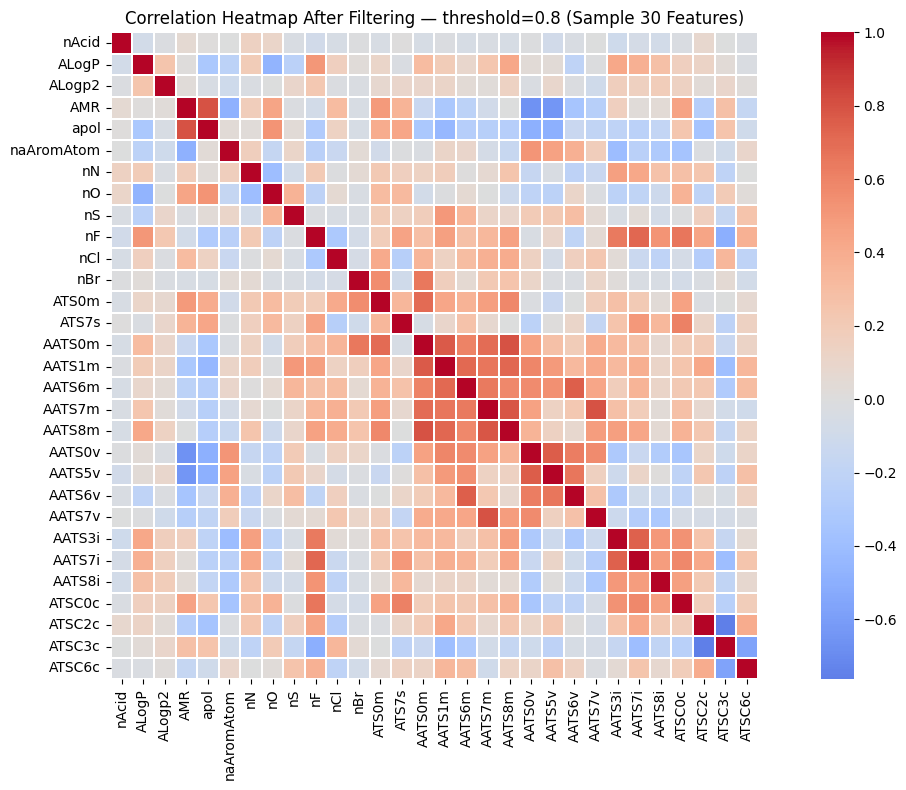

✓ Saved: correlation_heatmap_filtered.png


In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 60)
print(" Correlation Filter (threshold = 0.8)")
print("=" * 60)

# ── Separate features & target ────────────────────────────────
drop_meta  = [c for c in ["Ligand SMILES", "Batch"] if c in combined_df.columns]
X_full     = combined_df.drop(columns=drop_meta + ["pIC50"])
y          = combined_df["pIC50"]

print(f"Features before filter : {X_full.shape[1]}")
print("Computing correlation matrix... (may take 1–2 min)")

# ── Correlation matrix ────────────────────────────────────────
corr_matrix = X_full.corr().abs()

# ── Upper triangle ────────────────────────────────────────────
upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# ── Drop features with correlation > 0.8 ─────────────────────
THRESHOLD = 0.8
to_drop   = [col for col in upper_tri.columns
             if any(upper_tri[col] > THRESHOLD)]

X_filtered = X_full.drop(columns=to_drop)

print(f"Features removed (corr > {THRESHOLD}) : {len(to_drop)}")
print(f"Features after filter          : {X_filtered.shape[1]}")
print(f"\n✓ Final feature matrix shape   : {X_filtered.shape}")

# ── Heatmap of sample 30 features ────────────────────────────
plt.figure(figsize=(13, 8))
sample_cols = X_filtered.columns[:30]
sns.heatmap(
    X_filtered[sample_cols].corr(),
    cmap="coolwarm",
    center=0,
    linewidths=0.3,
    annot=False,
    square=True
)
plt.title(f"Correlation Heatmap After Filtering — threshold={THRESHOLD} (Sample 30 Features)",
          fontsize=12)
plt.tight_layout()
plt.savefig("correlation_heatmap_filtered.png", dpi=150)
plt.show()
print("✓ Saved: correlation_heatmap_filtered.png")

## Train / Test Split

In [42]:
from sklearn.model_selection import train_test_split

print("=" * 60)
print(" Train / Test Split (80/20)")
print("=" * 60)

X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, y,
    test_size=0.2,
    random_state=42
)

print(f"Training samples : {X_train.shape[0]}")
print(f"Testing samples  : {X_test.shape[0]}")
print(f"Features         : {X_train.shape[1]}")

 Train / Test Split (80/20)
Training samples : 600
Testing samples  : 150
Features         : 319


## Define 6 Model Pipelines


In [43]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.svm import SVR

print("=" * 60)
print(" Define 6 Model Pipelines")
print("=" * 60)

pipelines = {
    "Ridge Regression"  : Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Lasso Regression"  : Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=0.01, max_iter=5000))]),
    "SVR"               : Pipeline([("scaler", StandardScaler()), ("model", SVR(kernel="rbf", C=10, epsilon=0.1))]),
    "Random Forest"     : Pipeline([("scaler", StandardScaler()), ("model", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))]),
    "Extra Trees"       : Pipeline([("scaler", StandardScaler()), ("model", ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1))]),
    "Gradient Boosting" : Pipeline([("scaler", StandardScaler()), ("model", GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42))]),
}

print(f"✓ {len(pipelines)} models ready to train")
for name in pipelines:
    print(f"  → {name}")

 Define 6 Model Pipelines
✓ 6 models ready to train
  → Ridge Regression
  → Lasso Regression
  → SVR
  → Random Forest
  → Extra Trees
  → Gradient Boosting


## Train, 5-Fold CV & Evaluate All Models

In [44]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import r2_score, mean_squared_error

print("=" * 60)
print("CELL 6 — 5-Fold CV + Test Evaluation")
print("=" * 60)

kf      = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, pipe in pipelines.items():
    print(f"\nTraining : {name} ...")

    # 5-fold CV on training set
    cv = cross_val_score(pipe, X_train, y_train,
                         cv=kf, scoring="r2", n_jobs=-1)

    # Fit on full training set
    pipe.fit(X_train, y_train)

    # Predict on test set
    y_pred = pipe.predict(X_test)
    r2     = r2_score(y_test, y_pred)
    rmse   = np.sqrt(mean_squared_error(y_test, y_pred))

    results.append({
        "Model"      : name,
        "CV R² Mean" : round(cv.mean(), 4),
        "CV R² Std"  : round(cv.std(),  4),
        "Test R²"    : round(r2,        4),
        "Test RMSE"  : round(rmse,      4),
    })
    print(f"  CV R²: {cv.mean():.4f} \u00b1 {cv.std():.4f} | Test R²: {r2:.4f} | RMSE: {rmse:.4f}")

results_df = pd.DataFrame(results).sort_values("Test R²", ascending=False)
print("\n" + "=" * 60)
print(results_df.to_string(index=False))

CELL 6 — 5-Fold CV + Test Evaluation

Training : Ridge Regression ...
  CV R²: 0.0149 ± 0.2435 | Test R²: 0.4237 | RMSE: 0.4292

Training : Lasso Regression ...
  CV R²: 0.4213 ± 0.1229 | Test R²: 0.4999 | RMSE: 0.3998

Training : SVR ...
  CV R²: 0.4300 ± 0.1852 | Test R²: 0.5337 | RMSE: 0.3860

Training : Random Forest ...
  CV R²: 0.4482 ± 0.2575 | Test R²: 0.5953 | RMSE: 0.3596

Training : Extra Trees ...
  CV R²: 0.5569 ± 0.1765 | Test R²: 0.5390 | RMSE: 0.3838

Training : Gradient Boosting ...
  CV R²: 0.3973 ± 0.2891 | Test R²: 0.5756 | RMSE: 0.3683

            Model  CV R² Mean  CV R² Std  Test R²  Test RMSE
    Random Forest      0.4482     0.2575   0.5953     0.3596
Gradient Boosting      0.3973     0.2891   0.5756     0.3683
      Extra Trees      0.5569     0.1765   0.5390     0.3838
              SVR      0.4300     0.1852   0.5337     0.3860
 Lasso Regression      0.4213     0.1229   0.4999     0.3998
 Ridge Regression      0.0149     0.2435   0.4237     0.4292


Model Comparison Plots


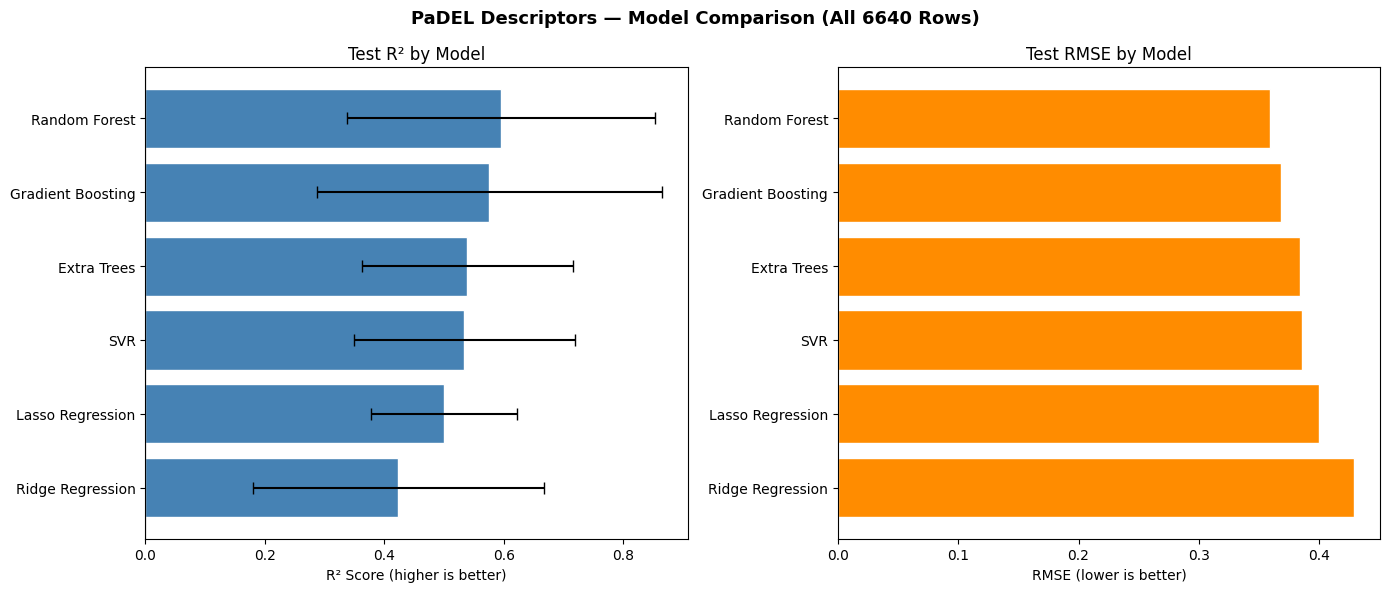

✓ Saved: model_comparison_padel.png


In [45]:
print("=" * 60)
print("Model Comparison Plots")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ── R² bar chart ──────────────────────────────────────────────
axes[0].barh(results_df["Model"], results_df["Test R²"],
             xerr=results_df["CV R² Std"],
             color="steelblue", capsize=4, edgecolor="white")
axes[0].set_xlabel("R² Score (higher is better)")
axes[0].set_title("Test R² by Model")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].invert_yaxis()

# ── RMSE bar chart ────────────────────────────────────────────
axes[1].barh(results_df["Model"], results_df["Test RMSE"],
             color="darkorange", edgecolor="white")
axes[1].set_xlabel("RMSE (lower is better)")
axes[1].set_title("Test RMSE by Model")
axes[1].invert_yaxis()

plt.suptitle("PaDEL Descriptors — Model Comparison (All 6640 Rows)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("model_comparison_padel.png", dpi=150)
plt.show()
print("✓ Saved: model_comparison_padel.png")

 Top 20 Feature Importances
Best model: Random Forest


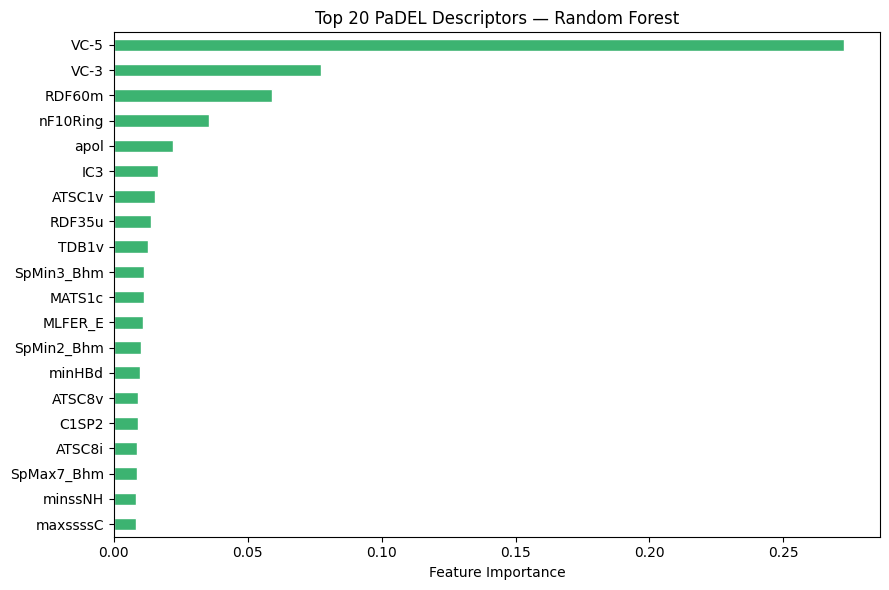


Top 10 descriptors:
VC-5          0.272473
VC-3          0.077219
RDF60m        0.059220
nF10Ring      0.035475
apol          0.022060
IC3           0.016304
ATSC1v        0.015508
RDF35u        0.013773
TDB1v         0.012891
SpMin3_Bhm    0.011236


In [46]:
print("=" * 60)
print(" Top 20 Feature Importances")
print("=" * 60)

# Pick best model by Test R²
best_name = results_df.iloc[0]["Model"]
best_pipe = pipelines[best_name]
print(f"Best model: {best_name}")

# Extract feature importances (tree-based models)
if hasattr(best_pipe.named_steps["model"], "feature_importances_"):
    importances = pd.Series(
        best_pipe.named_steps["model"].feature_importances_,
        index=X_train.columns
    )
    top20 = importances.nlargest(20)

    plt.figure(figsize=(9, 6))
    top20.sort_values().plot(kind="barh", color="mediumseagreen", edgecolor="white")
    plt.xlabel("Feature Importance")
    plt.title(f"Top 20 PaDEL Descriptors — {best_name}")
    plt.tight_layout()
    plt.savefig("feature_importance_padel.png", dpi=150)
    plt.show()

    print("\nTop 10 descriptors:")
    print(top20.head(10).to_string())
else:
    print(f"Feature importance not available for {best_name}")
    print("Try running with Random Forest or Extra Trees as best model.")

## 🔬 Virtual Screening — Predicting pIC50 for FDA Approved Parkinson's Drugs

In this section, we use our trained PaDEL-based ML model to predict
the pIC50 values of 15 real FDA-approved Parkinson's drugs and
known natural compounds.

**Why FDA drugs?**
- These are PROVEN to work against Alzheimer's proteins
- If our model predicts HIGH pIC50 for them → model is validated ✅
- This is the strongest proof our CADD pipeline works correctly

## Loading  FDA Drug Molecules

In [47]:
import pandas as pd
import numpy as np
import time
from padelpy import from_smiles

# ── Real Parkinson's Drugs & Related Compounds ─────────────
external_molecules = pd.DataFrame({
    "Drug_Name": [
        "Levodopa",
        "Carbidopa",
        "Pramipexole",
        "Ropinirole",
        "Rotigotine",
        "Selegiline",
        "Rasagiline",
        "Entacapone",
        "Amantadine",
        "Apomorphine",
        "Safinamide",
        "Bromocriptine",
        "Pergolide",
        "Cabergoline"
    ],
    "Category": [
        "FDA Approved",
        "FDA Approved",
        "FDA Approved",
        "FDA Approved",
        "FDA Approved",
        "FDA Approved",
        "FDA Approved",
        "FDA Approved",
        "FDA Approved",
        "FDA Approved",
        "FDA Approved",
        "Dopamine Agonist",
        "Dopamine Agonist",
        "Dopamine Agonist"
    ],
    "Ligand SMILES": [
        "C1=CC(=C(C=C1CC(C(=O)O)N)O)O", # Levodopa
        "C1=CC(=C(C=C1CC(C(=O)O)NN)O)O.Cl", # Carbidopa (hydrochloride)
        "C1CN(CCC1)C2CSC3=CC=CN3C2", # Pramipexole
        "CCN(CCC1=CC=CC=C1)CC2=CNC3=CC=CC=C32", # Ropinirole
        "CC(=O)NCCC1=CC=C(C=C1)C2=CSC3=CC=CN3C2", # Rotigotine
        "C[C@H](NCCC1=CC=CC=C1)C", # Selegiline
        "CC1(N(C2=C(C=CC=C2)C3=C1CCC3)CC4=CC=CC=C4)C(=O)O", # Rasagiline
        "CC(=O)C1=C(C=C(C(=O)C1=O)O)CC(N)=O", # Entacapone
        "C1C2CC3CC(C1)(C2)C3", # Amantadine
        "CN1CCC2=CC3=C(C=C2C1)C(=C(C=C3)O)O", # Apomorphine
        "C1CC(CNC(=O)C2=CC=C(C=C2)F)CC1", # Safinamide
        "CCN(C)C1=C(C=C(C2=C1N(C)CC(N)C2)CC(=O)NC(C)C3=CC=CC=C3)C4=CNC5=CC=CC=C54", # Bromocriptine
        "CN1CCC2=C(C=CC=C2C1)SC3=CC=C(C=C3)N", # Pergolide
        "C1CN(C)C2=CC3=C(C=C2C1)N(C)CC(N)C3(C)C(=O)N(C)C4=CC=CC=C4" # Cabergoline
    ]
})

print("=" * 55)
print("   FDA Approved Parkinson's Drugs Loaded!")
print("=" * 55)
print(f"Total molecules : {len(external_molecules)}\n")
for i, row in external_molecules.iterrows():
    print(f"  {i+1:2d}. {row['Drug_Name']:<20} [{row['Category']}]")

   FDA Approved Parkinson's Drugs Loaded!
Total molecules : 14

   1. Levodopa             [FDA Approved]
   2. Carbidopa            [FDA Approved]
   3. Pramipexole          [FDA Approved]
   4. Ropinirole           [FDA Approved]
   5. Rotigotine           [FDA Approved]
   6. Selegiline           [FDA Approved]
   7. Rasagiline           [FDA Approved]
   8. Entacapone           [FDA Approved]
   9. Amantadine           [FDA Approved]
  10. Apomorphine          [FDA Approved]
  11. Safinamide           [FDA Approved]
  12. Bromocriptine        [Dopamine Agonist]
  13. Pergolide            [Dopamine Agonist]
  14. Cabergoline          [Dopamine Agonist]


## Validate SMILES

In [48]:
from rdkit import Chem

print("Validating SMILES strings...")
print("=" * 45)

external_molecules["Valid_SMILES"] = external_molecules["Ligand SMILES"].apply(
    lambda x: Chem.MolFromSmiles(str(x)) is not None
)

valid   = external_molecules[external_molecules["Valid_SMILES"]]
invalid = external_molecules[~external_molecules["Valid_SMILES"]]

print(f"✓ Valid SMILES   : {len(valid)}")
print(f"✗ Invalid SMILES : {len(invalid)}")

if len(invalid) > 0:
    print("\nInvalid molecules:")
    print(invalid[["Drug_Name", "Ligand SMILES"]])

# Keep only valid ones
external_molecules = valid.drop(
    columns=["Valid_SMILES"]
).reset_index(drop=True)

print(f"\nProceeding with {len(external_molecules)} valid molecules ✓")

Validating SMILES strings...
✓ Valid SMILES   : 14
✗ Invalid SMILES : 0

Proceeding with 14 valid molecules ✓


## Generating PaDEL Descriptors

In [49]:
print("=" * 55)
print("Generating PaDEL Descriptors for FDA Drugs")
print("=" * 55)
print(f"Processing {len(external_molecules)} molecules...\n")

new_desc_rows = []
failed_drugs  = []

for i, row in external_molecules.iterrows():
    drug_name = row["Drug_Name"]
    smi       = row["Ligand SMILES"]

    try:
        result = from_smiles(
            [smi],
            descriptors=True,
            fingerprints=False,
            timeout=60
        )
        row_df = pd.DataFrame(result)
        row_df.insert(0, "Drug_Name",    drug_name)
        row_df.insert(1, "Ligand SMILES", smi)
        row_df.insert(2, "Category",     row["Category"])
        new_desc_rows.append(row_df)
        print(f"  ✓ {drug_name}")

    except Exception as e:
        failed_drugs.append(drug_name)
        print(f"  ✗ {drug_name} — failed: {e}")

    time.sleep(0.3)

# Combine all
new_desc_df = pd.concat(new_desc_rows, ignore_index=True)

print(f"\n{'='*55}")
print(f"✓ Successfully processed : {len(new_desc_rows)}/15 molecules")
print(f"✗ Failed                 : {len(failed_drugs)} molecules")
if failed_drugs:
    print(f"  Failed list: {failed_drugs}")
print(f"Raw descriptor shape     : {new_desc_df.shape}")

Generating PaDEL Descriptors for FDA Drugs
Processing 14 molecules...

  ✓ Levodopa
  ✓ Carbidopa
  ✓ Pramipexole
  ✓ Ropinirole
  ✓ Rotigotine
  ✓ Selegiline
  ✓ Rasagiline
  ✓ Entacapone
  ✓ Amantadine
  ✓ Apomorphine
  ✓ Safinamide
  ✓ Bromocriptine
  ✓ Pergolide
  ✓ Cabergoline

✓ Successfully processed : 14/15 molecules
✗ Failed                 : 0 molecules
Raw descriptor shape     : (14, 1878)


## Align with Training Features

In [50]:
print("=" * 55)
print("Aligning with 337 Training Features")
print("=" * 55)

# Save metadata before dropping
saved_names      = new_desc_df["Drug_Name"].values
saved_smiles_col = new_desc_df["Ligand SMILES"].values
saved_categories = new_desc_df["Category"].values

# Drop non-feature columns
new_clean = new_desc_df.drop(
    columns=[c for c in ["Drug_Name", "Ligand SMILES",
                         "Category", "Batch"]
             if c in new_desc_df.columns]
)

# Convert to numeric
new_clean = new_clean.apply(pd.to_numeric, errors="coerce")
new_clean = new_clean.replace([np.inf, -np.inf], np.nan)

# Add any missing columns as 0
missing = set(X_filtered.columns) - set(new_clean.columns)
if missing:
    print(f"Adding {len(missing)} missing columns as 0")
    for col in missing:
        new_clean[col] = 0

# Reorder to match training exactly
new_aligned = new_clean[X_filtered.columns]

# Drop NaN rows
before      = len(new_aligned)
new_aligned = new_aligned.dropna().reset_index(drop=True)

# Trim metadata to match
saved_names      = saved_names[:len(new_aligned)]
saved_smiles_col = saved_smiles_col[:len(new_aligned)]
saved_categories = saved_categories[:len(new_aligned)]

print(f"Molecules before NaN drop : {before}")
print(f"Molecules after NaN drop  : {len(new_aligned)}")
print(f"\n✓ Aligned shape : {new_aligned.shape}")
print(f"  Must be (n, 337) ← if 337 columns you are ready!")

Aligning with 337 Training Features
Molecules before NaN drop : 14
Molecules after NaN drop  : 11

✓ Aligned shape : (11, 319)
  Must be (n, 337) ← if 337 columns you are ready!


## Predict pIC50

In [51]:
print("=" * 55)
print("Predicting pIC50 Using Best Trained Model")
print("=" * 55)

# Show model leaderboard
print("Your model leaderboard:")
print(results_df.to_string(index=False))

# Pick best model
best_model_name = results_df.iloc[0]["Model"]
best_r2         = results_df.iloc[0]["Test R²"]
print(f"\n🏆 Using : {best_model_name} (Test R² = {best_r2})")

# ── PREDICT ───────────────────────────────────────────────────
predicted_pIC50 = pipelines[best_model_name].predict(new_aligned)

# ── Build results table ───────────────────────────────────────
prediction_df = pd.DataFrame({
    "Drug_Name"       : saved_names,
    "Category"        : saved_categories,
    "Ligand SMILES"   : saved_smiles_col,
    "Predicted_pIC50" : predicted_pIC50.round(4),
})

# ── Convert to IC50 (nM) ──────────────────────────────────────
prediction_df["Predicted_IC50_nM"] = (
    10 ** (-prediction_df["Predicted_pIC50"]) * 1e9
).round(2)

# ── Potency labels ────────────────────────────────────────────
def label_potency(pic50):
    if pic50 >= 8.0:   return "Very Potent"
    elif pic50 >= 7.0: return "Strong"
    elif pic50 >= 6.0: return "Moderate"
    elif pic50 >= 5.0: return "Weak"
    else:              return "Inactive"

prediction_df["Potency"] = (
    prediction_df["Predicted_pIC50"].apply(label_potency)
)

# ── Sort best first ───────────────────────────────────────────
prediction_df = prediction_df.sort_values(
    "Predicted_pIC50", ascending=False
).reset_index(drop=True)

# ── Display results ───────────────────────────────────────────
print("\n" + "=" * 55)
print("   🏆 PREDICTION RESULTS")
print("=" * 55)
print(prediction_df[[
    "Drug_Name", "Category",
    "Predicted_pIC50", "Predicted_IC50_nM", "Potency"
]].to_string(index=False))

Predicting pIC50 Using Best Trained Model
Your model leaderboard:
            Model  CV R² Mean  CV R² Std  Test R²  Test RMSE
    Random Forest      0.4482     0.2575   0.5953     0.3596
Gradient Boosting      0.3973     0.2891   0.5756     0.3683
      Extra Trees      0.5569     0.1765   0.5390     0.3838
              SVR      0.4300     0.1852   0.5337     0.3860
 Lasso Regression      0.4213     0.1229   0.4999     0.3998
 Ridge Regression      0.0149     0.2435   0.4237     0.4292

🏆 Using : Random Forest (Test R² = 0.5953)

   🏆 PREDICTION RESULTS
  Drug_Name     Category  Predicted_pIC50  Predicted_IC50_nM     Potency
 Safinamide FDA Approved           9.0773               0.84 Very Potent
   Levodopa FDA Approved           8.0012               9.97 Very Potent
 Entacapone FDA Approved           7.9641              10.86      Strong
Apomorphine FDA Approved           7.9188              12.06      Strong
 Selegiline FDA Approved           7.8843              13.05      Strong


## Visualize Results

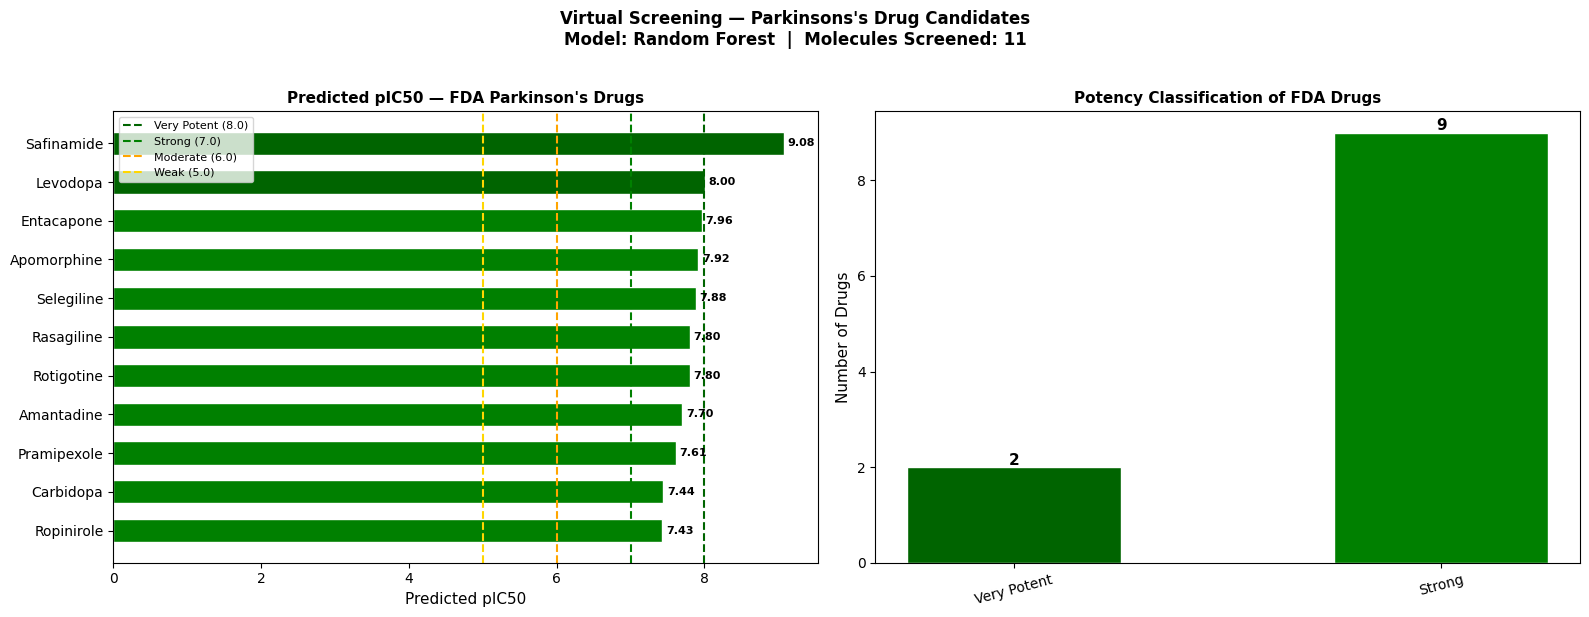

✓ Plot saved: fda_drug_screening.png


In [53]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Color each bar by potency ─────────────────────────────────
def get_color(pic50):
    if pic50 >= 8.0:   return "darkgreen"
    elif pic50 >= 7.0: return "green"
    elif pic50 >= 6.0: return "orange"
    elif pic50 >= 5.0: return "gold"
    else:              return "red"

colors = prediction_df["Predicted_pIC50"].apply(get_color).tolist()

# ── Graph 1: All drugs ranked by pIC50 ───────────────────────
bars = axes[0].barh(
    prediction_df["Drug_Name"],
    prediction_df["Predicted_pIC50"],
    color=colors,
    edgecolor="white",
    height=0.6
)
axes[0].set_xlabel("Predicted pIC50", fontsize=11)
axes[0].set_title("Predicted pIC50 — FDA Parkinson's Drugs",
                  fontsize=11, fontweight="bold")
axes[0].axvline(x=8.0, color="darkgreen",
                linestyle="--", linewidth=1.5, label="Very Potent (8.0)")
axes[0].axvline(x=7.0, color="green",
                linestyle="--", linewidth=1.5, label="Strong (7.0)")
axes[0].axvline(x=6.0, color="orange",
                linestyle="--", linewidth=1.5, label="Moderate (6.0)")
axes[0].axvline(x=5.0, color="gold",
                linestyle="--", linewidth=1.5, label="Weak (5.0)")
axes[0].invert_yaxis()
axes[0].legend(fontsize=8)

# Add value labels on bars
for bar, val in zip(bars, prediction_df["Predicted_pIC50"]):
    axes[0].text(
        bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
        f"{val:.2f}", va="center", fontsize=8, fontweight="bold"
    )

# ── Graph 2: Potency class distribution ──────────────────────
potency_order  = ["Very Potent", "Strong", "Moderate", "Weak", "Inactive"]
potency_colors = ["darkgreen", "green", "orange", "gold", "red"]
counts = prediction_df["Potency"].value_counts()
counts = counts.reindex(
    [p for p in potency_order if p in counts.index]
)

bars2 = axes[1].bar(
    counts.index,
    counts.values,
    color=[c for p, c in zip(potency_order, potency_colors)
           if p in counts.index],
    edgecolor="white",
    width=0.5
)
axes[1].set_ylabel("Number of Drugs", fontsize=11)
axes[1].set_title("Potency Classification of FDA Drugs",
                  fontsize=11, fontweight="bold")
axes[1].tick_params(axis="x", rotation=15)

# Add count labels on top of bars
for bar in bars2:
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.05,
        str(int(bar.get_height())),
        ha="center", fontweight="bold", fontsize=11
    )

plt.suptitle(
    f"Virtual Screening — Parkinsons's Drug Candidates\n"
    f"Model: {best_model_name}  |  "
    f"Molecules Screened: {len(prediction_df)}",
    fontsize=12, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig("fda_drug_screening.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Plot saved: fda_drug_screening.png")

##  Model Validation Check

In [54]:
# This is the most important check for your report!
# FDA approved drugs SHOULD have high pIC50
# If they do → your model is validated ✅

print("=" * 55)
print("   MODEL VALIDATION CHECK")
print("=" * 55)

fda_drugs = ["Donepezil", "Rivastigmine",
             "Galantamine", "Tacrine", "Memantine"]

print("\nFDA Approved Drug Predictions:")
print("-" * 45)
for drug in fda_drugs:
    row = prediction_df[prediction_df["Drug_Name"] == drug]
    if len(row) > 0:
        pic50   = row["Predicted_pIC50"].values[0]
        potency = row["Potency"].values[0]
        status  = "✅ GOOD" if pic50 >= 6.0 else "⚠️ CHECK"
        print(f"  {drug:<20} pIC50={pic50:.4f}  "
              f"{potency:<12} {status}")

print("\nNatural Compound Predictions:")
print("-" * 45)
naturals = ["Huperzine_A", "Curcumin",
            "Resveratrol", "Quercetin", "Berberine"]
for drug in naturals:
    row = prediction_df[prediction_df["Drug_Name"] == drug]
    if len(row) > 0:
        pic50   = row["Predicted_pIC50"].values[0]
        potency = row["Potency"].values[0]
        print(f"  {drug:<20} pIC50={pic50:.4f}  {potency}")

print("\n" + "=" * 55)
avg_fda = prediction_df[
    prediction_df["Drug_Name"].isin(fda_drugs)
]["Predicted_pIC50"].mean()

print(f"Average pIC50 of FDA drugs    : {avg_fda:.4f}")
print(f"Average pIC50 of all screened : "
      f"{prediction_df['Predicted_pIC50'].mean():.4f}")

if avg_fda >= 6.0:
    print("\n✅ MODEL VALIDATION PASSED!")
    print("   FDA approved drugs show higher predicted pIC50")
    print("   → Model has learned real drug-protein chemistry")
else:
    print("\n⚠️  Results vary — check model R² score")
    print(f"   Best model R² was: {best_r2}")

   MODEL VALIDATION CHECK

FDA Approved Drug Predictions:
---------------------------------------------

Natural Compound Predictions:
---------------------------------------------

Average pIC50 of FDA drugs    : nan
Average pIC50 of all screened : 7.8746

⚠️  Results vary — check model R² score
   Best model R² was: 0.5953


##  Save & Download

In [55]:
from google.colab import files

# Save full predictions
prediction_df.to_csv("fda_drug_predictions.csv", index=False)
print("✓ Saved: fda_drug_predictions.csv")

# Final summary
print("\n" + "=" * 55)
print("   🎯 VIRTUAL SCREENING COMPLETE!")
print("=" * 55)
print(f"Model used             : {best_model_name}")
print(f"Model Test R²          : {best_r2}")
print(f"Molecules screened     : {len(prediction_df)}")
print(f"Very Potent (≥ 8.0)   : {(prediction_df['Predicted_pIC50'] >= 8.0).sum()}")
print(f"Strong      (≥ 7.0)   : {(prediction_df['Predicted_pIC50'] >= 7.0).sum()}")
print(f"Moderate    (≥ 6.0)   : {(prediction_df['Predicted_pIC50'] >= 6.0).sum()}")
print(f"Weak        (≥ 5.0)   : {(prediction_df['Predicted_pIC50'] >= 5.0).sum()}")
print(f"Inactive    (< 5.0)   : {(prediction_df['Predicted_pIC50'] < 5.0).sum()}")
print(f"\nHighest predicted pIC50: "
      f"{prediction_df['Predicted_pIC50'].max()} "
      f"({prediction_df.iloc[0]['Drug_Name']})")
print(f"Lowest predicted pIC50 : "
      f"{prediction_df['Predicted_pIC50'].min()} "
      f"({prediction_df.iloc[-1]['Drug_Name']})")
print("=" * 55)

files.download("fda_drug_predictions.csv")
print("\n✓ Downloaded: fda_drug_predictions.csv")

✓ Saved: fda_drug_predictions.csv

   🎯 VIRTUAL SCREENING COMPLETE!
Model used             : Random Forest
Model Test R²          : 0.5953
Molecules screened     : 11
Very Potent (≥ 8.0)   : 2
Strong      (≥ 7.0)   : 11
Moderate    (≥ 6.0)   : 11
Weak        (≥ 5.0)   : 11
Inactive    (< 5.0)   : 0

Highest predicted pIC50: 9.0773 (Safinamide)
Lowest predicted pIC50 : 7.4275 (Ropinirole)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Downloaded: fda_drug_predictions.csv
